# RQ1: Predicting the Dollar Amount Paid, Nationally and by Region

**RQ1:** Can we predict the dollar amount paid on a building claim using flood-zone, construction, policy and geographic features?

This notebook answers RQ1 for **four scopes**: the whole country, the **Florida Peninsula**, the **Gulf Coast**
and the **Mid-Atlantic & Northeast Coast**. It uses the feature set that notebook 05 found best
(all 14 groups of pre-loss features, including the storm and county history).

For every scope we compare:

| Comparison | Question it answers |
|---|---|
| 15 features (notebook 03) vs **all 14 groups** | Do the extra features help? |
| **National model** vs **regional model** | Is a model trained only on this region better? |
| **A. known storms** (random 70/30 split) vs **B. new storms** (train 2020-2023, test 2024-2025) | Does it work for a storm the model has never seen? |
| **5-fold cross validation**, fewer features, PCA (Section 4) | Do the scores hold up? How many features are needed? Does PCA help? |

**Model:** gradient boosting with Poisson loss, trained on **dollars**. **Score:** R² in dollars, median and mean error in dollars.
Only facts known **when a claim is reported** are used. Random seed = 42.

---
# Section 0: Setup, data and features

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance
import warnings; warnings.filterwarnings('ignore')
SEED = 42
pd.set_option('display.max_columns', 60)

work = pd.read_parquet('outputs/nfip_claims_simple_clean.parquet')
keys = pd.read_parquet('outputs/nfip_claims_simple_keys.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet',
                      columns=['id', 'baseFloodElevation', 'lowestFloorElevation', 'floodZoneCurrent', 'yearOfLoss'])
raw = raw[raw['yearOfLoss'].between(2020, 2025)].drop(columns='yearOfLoss')
extra = keys[['id', 'countyCode']].merge(raw, on='id', how='left')      # same row order as work
for c in ['countyCode', 'baseFloodElevation', 'lowestFloorElevation', 'floodZoneCurrent']:
    work[c] = extra[c].values
for c in ['baseFloodElevation', 'lowestFloorElevation']:
    work[c] = work[c].astype(float)
    work.loc[work[c].abs() >= 9000, c] = np.nan                         # 9990 / 9999 placeholders

paid = work[work['is_paid'] == 1].copy()
paid['year'] = paid['dateOfLoss'].dt.year
paid['occupancyType'] = paid['occupancyType'].replace({1: 11, 2: 12, 3: 13, 4: 18, 6: 18})   # legacy codes
REGIONS = {'Florida Peninsula': ['FL'], 'Gulf Coast': ['LA', 'TX', 'MS', 'AL'],
           'Mid-Atlantic & Northeast': ['NJ', 'NY', 'CT', 'RI', 'MA', 'MD', 'DE', 'DC', 'NH', 'ME']}
paid['region'] = 'Other'
for name, states in REGIONS.items():
    paid.loc[paid['state'].isin(states), 'region'] = name
print(f'Paid claims: {len(paid):,}')
print(paid['region'].value_counts())

Paid claims: 212,932
region
Florida Peninsula           120637
Other                        36583
Gulf Coast                   34660
Mid-Atlantic & Northeast     21052
Name: count, dtype: int64


In [2]:
def zone_family(z):
    z = str(z).upper()
    if z in ['X', 'B', 'C']: return 'X'
    if z.startswith('V'): return 'V'
    if z in ['AE', 'AH', 'AO', 'A99', 'A']: return z
    if z.startswith('A'): return 'AE'
    return 'other'
DED = {'0': 500, '1': 1000, '2': 2000, '3': 3000, '4': 4000, '5': 5000, '9': 750, 'A': 10000, 'B': 15000, 'C': 20000,
       'D': 25000, 'E': 50000, 'F': 1250, 'G': 1500, 'H': 200}
F = pd.DataFrame(index=paid.index)
F['bldg_coverage'] = paid['totalBuildingInsuranceCoverage']
F['contents_coverage'] = paid['totalContentsInsuranceCoverage']
F['bldg_deductible'] = paid['bldg_deductible_usd']
F['contents_deductible'] = paid['contentsDeductibleCode'].map(DED).fillna(0)
F['policy_count'] = paid['policyCount']
F['units'] = paid['numberOfUnits']
F['building_age'] = paid['building_age']
F['post_firm'] = paid['postFIRMConstructionIndicator']
F['policy_tenure'] = (paid['dateOfLoss'] - paid['originalNBDate']).dt.days / 365.25
F['elevated'] = paid['elevatedBuildingIndicator']
F['elevation_difference'] = paid['elevationDifference']
F['base_flood_elevation'] = paid['baseFloodElevation']
F['lowest_floor_elevation'] = paid['lowestFloorElevation']
F['has_elevation_data'] = paid['elevationDifference'].notna().astype(int)
F['crs_class'] = paid['crsClassCode']
F['crs_unknown'] = paid['crsClassCode_missing']
F['risk_rating_2'] = (paid['rateMethod'] == 'RE').astype(int)
F['primary_residence'] = paid['primaryResidenceIndicator']
F['rental'] = paid['rentalPropertyIndicator']
F['small_business'] = paid['smallBusinessIndicatorBuilding']
F['latitude'] = paid['latitude']; F['longitude'] = paid['longitude']
F['loss_month'] = paid['loss_month']
F['loss_year'] = paid['year']
F['report_lag'] = paid['report_lag_days']
F['named_storm'] = paid['is_named_event']
F['county_frequency'] = paid['countyCode'].map(paid['countyCode'].value_counts(normalize=True)).fillna(0)
ONE_HOT = {'occupancy': paid['occupancyType'].astype(str), 'condo_type': paid['condominiumCoverageTypeCode'].astype(str),
           'building_use': paid['buildingDescriptionCode'].astype(str), 'foundation': paid['foundationType'].astype(str),
           'basement': paid['basementEnclosureCrawlspaceType'].astype(str), 'obstruction': paid['obstructionType'].astype(str),
           'floors': paid['numberOfFloorsInTheInsuredBuilding'].astype(str), 'contents_location': paid['locationOfContents'].astype(str),
           'zone_rated': paid['flood_zone_family'], 'zone_current': paid['floodZoneCurrent'].map(zone_family).fillna('none'),
           'state': paid['state_group']}
for name, col in ONE_HOT.items():
    d = pd.get_dummies(col, prefix=name, dtype=int)
    F = pd.concat([F, d.loc[:, d.mean() >= 0.002]], axis=1)
ALL_FEATURES = list(F.columns)

with open('outputs/simple_feature_lists.json') as f:
    FL = json.load(f)
X15 = pd.get_dummies(work[FL['NOMINAL_FEATURES'] + FL['NUMERIC_FEATURES']], columns=FL['NOMINAL_FEATURES'], dtype=int).loc[paid.index, FL['RQ1']]
print(f'All-groups feature set: {len(ALL_FEATURES)} columns + county_history + storm_history')
print(f'Notebook 03 feature set: {X15.shape[1]} columns')

All-groups feature set: 104 columns + county_history + storm_history
Notebook 03 feature set: 15 columns


**Storm and county history** are made from the **training rows only** of each model:
the average log payment of earlier claims in the same named storm (or county), pulled toward the overall average when there are few claims.
A storm or county with no training claims gets the overall average. The storm name is known when a claim is reported.

In [3]:
y = paid['amountPaidOnBuildingClaim']
ylog = np.log1p(y)
storm = paid['floodEvent'].where(paid['floodEvent'] != 'no_named_event', 'none')

def history(key, tr_idx, all_idx, k=30):
    g = pd.DataFrame({'k': key.loc[tr_idx], 'y': ylog.loc[tr_idx]}).groupby('k')['y'].agg(['mean', 'size'])
    glob = ylog.loc[tr_idx].mean()
    return key.loc[all_idx].map((g['mean'] * g['size'] + glob * k) / (g['size'] + k)).fillna(glob).values

def design(feature_set, tr_idx, te_idx):
    if feature_set == '15 features':
        return X15.loc[tr_idx], X15.loc[te_idx]
    Xtr, Xte = F.loc[tr_idx].copy(), F.loc[te_idx].copy()
    for name, key in [('county_history', paid['countyCode']), ('storm_history', storm)]:
        Xtr[name] = history(key, tr_idx, tr_idx); Xte[name] = history(key, tr_idx, te_idx)
    return Xtr, Xte

def model():
    return HistGradientBoostingRegressor(loss='poisson', max_iter=400, learning_rate=0.05, max_leaf_nodes=31, random_state=SEED)

def scores(true, pred):
    return {'R2 dollars': r2_score(true, pred), 'median error $': np.median(np.abs(true - pred)),
            'mean error $': mean_absolute_error(true, pred)}

A_train, A_test = train_test_split(paid.index, test_size=0.3, random_state=SEED)
SPLITS = {'A. known storms': (pd.Index(A_train), pd.Index(A_test)),
          'B. new storms': (paid.index[paid['year'] <= 2023], paid.index[paid['year'] >= 2024])}
for s, (tr, te) in SPLITS.items():
    print(f'{s:16s} train {len(tr):>7,}  test {len(te):>7,}')

A. known storms  train 149,052  test  63,880
B. new storms    train 119,746  test  93,186


---
# Section 1: Train the models

For each split we train:
- **national** models on all regions (15 features, and all groups), then score them on the whole country and on each region's test claims;
- **regional** models on one region's training claims only, and score them on that region's test claims.

In [4]:
rows, keep = [], {}
for split, (tr, te) in SPLITS.items():
    for fs in ['15 features', 'all groups']:
        Xa, Xb = design(fs, tr, te)
        m = model().fit(Xa, y.loc[tr]); p = pd.Series(m.predict(Xb), index=te)
        keep[(split, 'national', fs)] = (m, Xb, p)
        for scope in ['National'] + list(REGIONS):
            idx = te if scope == 'National' else te[paid.loc[te, 'region'] == scope]
            rows.append({'split': split, 'scope': scope, 'model trained on': 'all regions', 'features': fs,
                         'test claims': len(idx), **scores(y.loc[idx], p.loc[idx])})
        for scope in REGIONS:
            tr_r, te_r = tr[paid.loc[tr, 'region'] == scope], te[paid.loc[te, 'region'] == scope]
            Xa, Xb = design(fs, tr_r, te_r)
            m = model().fit(Xa, y.loc[tr_r]); p = m.predict(Xb)
            keep[(split, scope, fs)] = (m, Xb, pd.Series(p, index=te_r))
            rows.append({'split': split, 'scope': scope, 'model trained on': 'this region only', 'features': fs,
                         'test claims': len(te_r), **scores(y.loc[te_r], p)})
results = pd.DataFrame(rows)
print('Models trained:', len(keep))

Models trained: 16


---
# Section 2: Results

## 2.1 Known storms (random 70/30 split)

In [5]:
def table(split):
    t = results[results['split'] == split].copy()
    t['model'] = t['model trained on'] + ', ' + t['features']
    return t.pivot_table(index='scope', columns='model', values='R2 dollars').reindex(['National'] + list(REGIONS))
tA = table('A. known storms')
tA.round(3)

model,"all regions, 15 features","all regions, all groups","this region only, 15 features","this region only, all groups"
scope,,,,
National,0.566,0.649,NaN,NaN
Florida Peninsula,0.567,0.660,0.609,0.670
Gulf Coast,0.395,0.416,0.425,0.458
Mid-Atlantic & Northeast,0.290,0.304,0.282,0.311


In [6]:
fmt = {'R2 dollars': '{:.3f}', 'median error $': '${:,.0f}', 'mean error $': '${:,.0f}', 'test claims': '{:,}'}
best_A = (results[results['split'] == 'A. known storms'].sort_values('R2 dollars', ascending=False)
          .groupby('scope').head(1).set_index('scope').reindex(['National'] + list(REGIONS)))
best_A[['model trained on', 'features', 'test claims', 'R2 dollars', 'median error $', 'mean error $']].style.format(fmt)

,model trained on,features,test claims,R2 dollars,median error $,mean error $
scope,,,,,,
National,all regions,all groups,"63,880",0.649,"$22,462","$39,601"
Florida Peninsula,this region only,all groups,"36,268",0.670,"$28,078","$46,531"
Gulf Coast,this region only,all groups,"10,385",0.458,"$17,741","$26,623"
Mid-Atlantic & Northeast,this region only,all groups,"6,260",0.311,"$13,215","$26,787"


## 2.2 New storms (train 2020-2023, test 2024-2025)

In [7]:
tB = table('B. new storms')
tB.round(3)

model,"all regions, 15 features","all regions, all groups","this region only, 15 features","this region only, all groups"
scope,,,,
National,-0.059,-0.370,NaN,NaN
Florida Peninsula,-0.114,-0.460,-0.389,-0.288
Gulf Coast,0.128,0.117,-0.000,0.018
Mid-Atlantic & Northeast,0.251,0.302,0.162,0.213


In [8]:
best_B = (results[results['split'] == 'B. new storms'].sort_values('R2 dollars', ascending=False)
          .groupby('scope').head(1).set_index('scope').reindex(['National'] + list(REGIONS)))
best_B[['model trained on', 'features', 'test claims', 'R2 dollars', 'median error $', 'mean error $']].style.format(fmt)

,model trained on,features,test claims,R2 dollars,median error $,mean error $
scope,,,,,,
National,all regions,15 features,"93,186",-0.059,"$30,378","$57,036"
Florida Peninsula,all regions,15 features,"67,026",-0.114,"$36,715","$65,317"
Gulf Coast,all regions,15 features,"8,133",0.128,"$22,604","$34,543"
Mid-Atlantic & Northeast,all regions,all groups,"3,958",0.302,"$12,941","$26,402"


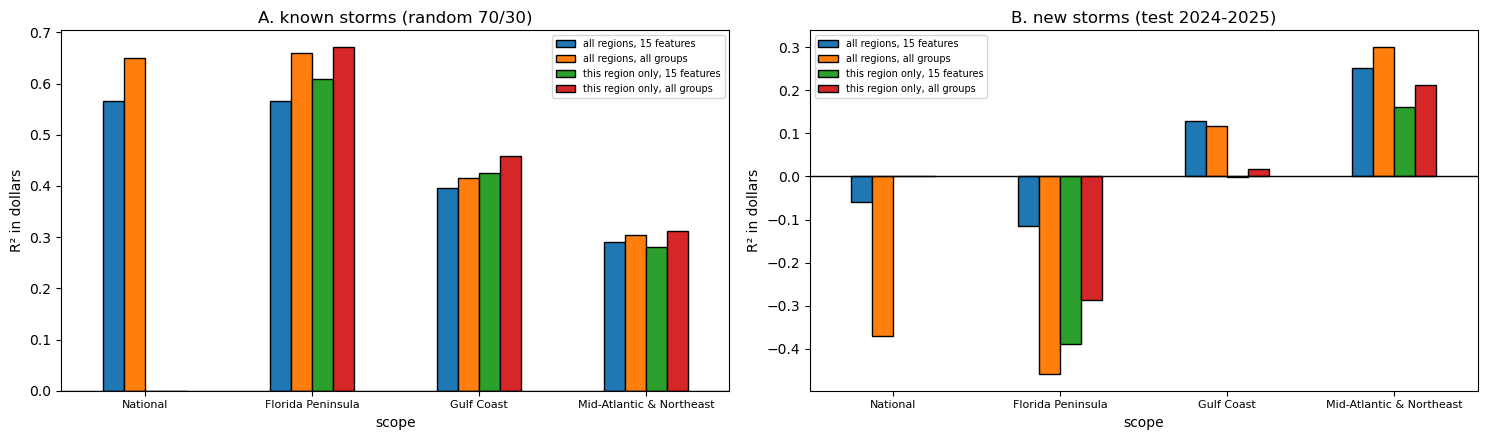

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
for a, t, title in [(ax[0], tA, 'A. known storms (random 70/30)'), (ax[1], tB, 'B. new storms (test 2024-2025)')]:
    t.plot.bar(ax=a, edgecolor='black', rot=0)
    a.axhline(0, color='black', lw=1); a.set_title(title); a.set_ylabel('R² in dollars'); a.tick_params(axis='x', labelsize=8)
    a.legend(fontsize=7)
plt.tight_layout(); plt.show()

---
# Section 3: Which features matter in each scope? (best known-storm model)

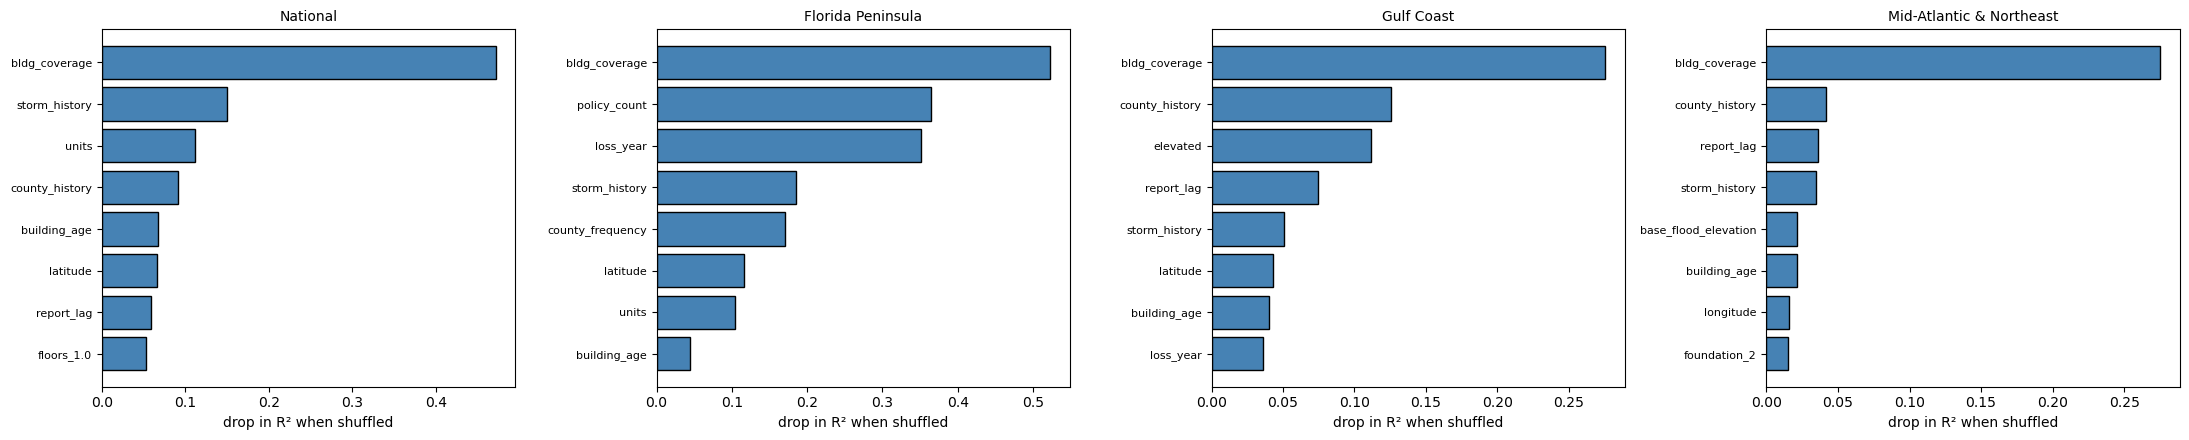

,National,Florida Peninsula,Gulf Coast,Mid-Atlantic & Northeast
0,bldg_coverage (0.47),bldg_coverage (0.52),bldg_coverage (0.28),bldg_coverage (0.28)
1,storm_history (0.15),policy_count (0.36),county_history (0.13),county_history (0.04)
2,units (0.11),loss_year (0.35),elevated (0.11),report_lag (0.04)
3,county_history (0.09),storm_history (0.19),report_lag (0.07),storm_history (0.03)
4,building_age (0.07),county_frequency (0.17),storm_history (0.05),base_flood_elevation (0.02)
5,latitude (0.07),latitude (0.12),latitude (0.04),building_age (0.02)
6,report_lag (0.06),units (0.10),building_age (0.04),longitude (0.02)
7,floors_1.0 (0.05),building_age (0.04),loss_year (0.04),foundation_2 (0.02)


In [10]:
imps = {}
for scope in ['National'] + list(REGIONS):
    best = best_A.loc[scope]
    key = ('A. known storms', 'national' if best['model trained on'] == 'all regions' else scope, best['features'])
    m, Xb, p = keep[key]
    if scope != 'National' and key[1] == 'national':
        Xb = Xb.loc[paid.loc[Xb.index, 'region'] == scope]
    sub = np.random.default_rng(SEED).choice(len(Xb), min(6000, len(Xb)), replace=False)
    pi = permutation_importance(m, Xb.iloc[sub], y.loc[Xb.index[sub]], scoring='r2', n_repeats=3, random_state=SEED)
    imps[scope] = pd.Series(pi.importances_mean, index=Xb.columns).sort_values(ascending=False).head(8)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for a, (scope, imp) in zip(axes, imps.items()):
    a.barh(imp.index[::-1], imp.values[::-1], color='steelblue', edgecolor='black')
    a.set_title(scope, fontsize=10); a.set_xlabel('drop in R² when shuffled'); a.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame({s: [f'{f} ({v:.2f})' for f, v in imp.items()] for s, imp in imps.items()})

---
# Section 4: Checking the results with 5-fold cross validation

Sections 1-3 used **one** random 70/30 split. One split can be lucky or unlucky, so here we use **5-fold cross validation**:
the claims are cut into 5 parts, each part is the test set once, and we report the **average R² of the 5 folds** (± the spread).

Each model is trained **on one scope's claims only** (national, or one region). The storm and county history are rebuilt
from the training folds every time, so the test fold never leaks into the features.

We run three checks:

| Check | Question |
|---|---|
| 4.1 Cross validation | Do the scores from the single split hold up? Also for new storms (one loss year left out per fold)? |
| 4.2 Fewer features | Can we keep the score with fewer features? |
| 4.3 PCA vs original columns | Does PCA help the regression? |

**Run time:** this section takes about **75 minutes** (about 300 models).

## 4.1 Cross validation: known storms and new storms

In [11]:
from sklearn.model_selection import KFold, GroupKFold
cv_rows = []
for scope in ['National'] + list(REGIONS):
    idx = paid.index if scope == 'National' else paid.index[paid['region'] == scope]
    for cvname, splitter, groups in [('known storms (5-fold random)', KFold(5, shuffle=True, random_state=SEED), None),
                                     ('new storms (5-fold by loss year)', GroupKFold(5), paid.loc[idx, 'year'].values)]:
        for fs in ['15 features', 'all groups']:
            r2 = []
            for a, b in splitter.split(idx, groups=groups):
                tr, te = idx[a], idx[b]
                Xa, Xb = design(fs, tr, te)
                r2.append(r2_score(y.loc[te], model().fit(Xa, y.loc[tr]).predict(Xb)))
            cv_rows.append({'scope': scope, 'cv': cvname, 'features': fs, 'mean R2': np.mean(r2), 'spread (std)': np.std(r2),
                            'R2 of each fold': ' '.join(f'{v:.2f}' for v in r2)})
cv = pd.DataFrame(cv_rows)
cv.round(3)

,scope,cv,features,mean R2,spread (std),R2 of each fold
0,National,known storms (5-fold random),15 features,0.553,0.007,0.54 0.56 0.56 0.55 0.55
1,National,known storms (5-fold random),all groups,0.571,0.063,0.65 0.62 0.60 0.50 0.49
2,National,new storms (5-fold by loss year),15 features,0.075,0.144,-0.17 0.13 0.23 0.01 0.19
3,National,new storms (5-fold by loss year),all groups,0.098,0.223,-0.31 0.08 0.29 0.12 0.31
4,Florida Peninsula,known storms (5-fold random),15 features,0.589,0.039,0.63 0.55 0.64 0.55 0.58
5,Florida Peninsula,known storms (5-fold random),all groups,0.667,0.027,0.70 0.68 0.67 0.66 0.62
6,Florida Peninsula,new storms (5-fold by loss year),15 features,-0.036,0.247,-0.39 0.10 0.25 -0.27 0.12
7,Florida Peninsula,new storms (5-fold by loss year),all groups,-0.017,0.268,-0.18 0.02 0.32 -0.43 0.20
8,Gulf Coast,known storms (5-fold random),15 features,0.438,0.026,0.43 0.39 0.45 0.45 0.46
9,Gulf Coast,known storms (5-fold random),all groups,0.467,0.034,0.46 0.40 0.49 0.49 0.49


In [12]:
single = {s: best_A.loc[s, 'R2 dollars'] for s in ['National'] + list(REGIONS)}
t = cv[cv['cv'].str.startswith('known') & (cv['features'] == 'all groups')].set_index('scope')
pd.DataFrame({'single 70/30 split (Section 2)': pd.Series(single),
              '5-fold CV mean': t['mean R2'], '5-fold CV spread': t['spread (std)'],
              'R2 of each fold': t['R2 of each fold']}).round(3)

,single 70/30 split (Section 2),5-fold CV mean,5-fold CV spread,R2 of each fold
National,0.649,0.571,0.063,0.65 0.62 0.60 0.50 0.49
Florida Peninsula,0.670,0.667,0.027,0.70 0.68 0.67 0.66 0.62
Gulf Coast,0.458,0.467,0.034,0.46 0.40 0.49 0.49 0.49
Mid-Atlantic & Northeast,0.311,0.368,0.051,0.27 0.40 0.39 0.38 0.40


**What the cross validation shows**
- **Florida and the Gulf Coast hold up:** the CV mean is almost the same as the single split.
- **The national 0.649 was a lucky split.** The 5 folds range from about 0.49 to 0.65 (mean about **0.57**). In dollars, a few
  multi-million-dollar condo claims dominate R², so the score depends on which fold they fall in.
- **The Mid-Atlantic & Northeast single split was a little unlucky** (CV mean about 0.37).
- **New storms:** when a whole loss year is left out, R² is only about 0 to 0.2, as in Section 2.2.

## 4.2 Fewer features: how many do we really need?

Inside **each fold** (training claims only):
1. Train the model with all 40 features (the 11 category features count as one feature each, with all their one-hot columns).
2. On 20% of the training claims held back, shuffle one feature at a time and measure how much R² drops (permutation importance).
3. Keep the top 3, 5, 8, 10, 15, 20 or all 40 features, retrain, and score on the test fold.

Because the ranking is made without the test fold, the scores are fair.

In [13]:
GROUPS = {}
for c in ALL_FEATURES:
    g = next((k for k in ONE_HOT if c.startswith(k + '_')), c)
    GROUPS.setdefault(g, []).append(c)
GROUPS['county_history'] = ['county_history']; GROUPS['storm_history'] = ['storm_history']
print('Features before one-hot encoding:', len(GROUPS), '  columns:', sum(len(v) for v in GROUPS.values()))
KS = [3, 5, 8, 10, 15, 20, 40]
rng = np.random.default_rng(SEED)

def rank_features(tr):
    fit_idx, val_idx = train_test_split(tr, test_size=0.2, random_state=SEED)
    Xa, Xv = design('all groups', fit_idx, val_idx)
    m = model().fit(Xa, y.loc[fit_idx])
    yv = y.loc[val_idx].values; base = r2_score(yv, m.predict(Xv))
    drop = {}
    for g, cols in GROUPS.items():
        d = []
        for _ in range(2):
            Xp = Xv.copy(); perm = rng.permutation(len(Xp))
            Xp[cols] = Xv[cols].values[perm]
            d.append(base - r2_score(yv, m.predict(Xp)))
        drop[g] = np.mean(d)
    return pd.Series(drop).sort_values(ascending=False)

red_rows, ranks = [], []
for scope in ['National'] + list(REGIONS):
    idx = paid.index if scope == 'National' else paid.index[paid['region'] == scope]
    for fold, (a, b) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(idx)):
        tr, te = idx[a], idx[b]
        rk = rank_features(tr)
        ranks.append(rk.rename(f'{scope}|{fold}'))
        Xa, Xb = design('all groups', tr, te)
        for k in KS:
            cols = [c for g in rk.index[:k] for c in GROUPS[g]]
            p = model().fit(Xa[cols], y.loc[tr]).predict(Xb[cols])
            red_rows.append({'scope': scope, 'fold': fold, 'features kept': k, 'columns': len(cols), 'R2': r2_score(y.loc[te], p)})
red = pd.DataFrame(red_rows); ranks = pd.concat(ranks, axis=1)
red.groupby(['features kept', 'scope'])['R2'].mean().unstack().reindex(columns=['National'] + list(REGIONS)).round(3)

Features before one-hot encoding: 40   columns: 106


scope,National,Florida Peninsula,Gulf Coast,Mid-Atlantic & Northeast
features kept,,,,
3,0.339,0.305,0.302,0.243
5,0.447,0.457,0.347,0.282
8,0.529,0.575,0.393,0.301
10,0.578,0.639,0.406,0.317
15,0.594,0.647,0.444,0.338
20,0.590,0.655,0.457,0.351
40,0.571,0.667,0.467,0.368


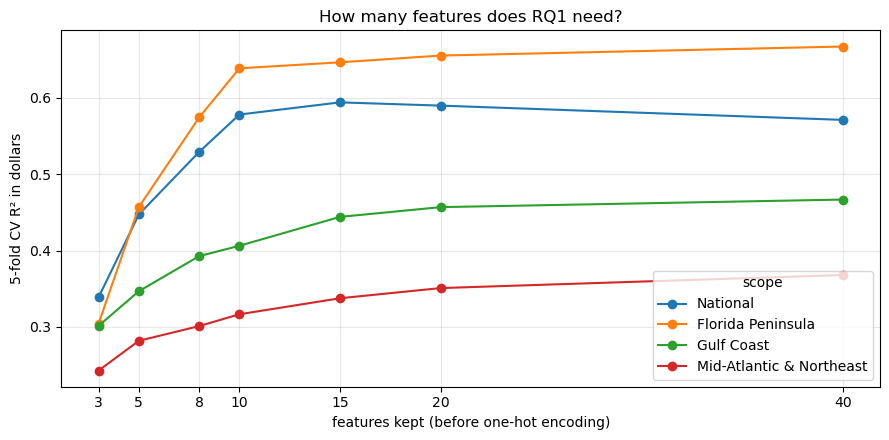

Top 8 features by average rank (in how many folds they were in the top 8):


,National,Florida Peninsula,Gulf Coast,Mid-Atlantic & Northeast
0,bldg_coverage (5/5),bldg_coverage (5/5),bldg_coverage (5/5),bldg_coverage (5/5)
1,loss_year (5/5),policy_count (5/5),county_history (5/5),report_lag (5/5)
2,policy_count (5/5),storm_history (5/5),elevated (5/5),foundation (5/5)
3,storm_history (4/5),units (5/5),report_lag (5/5),storm_history (5/5)
4,county_frequency (3/5),lowest_floor_elevation (4/5),storm_history (5/5),county_history (5/5)
5,lowest_floor_elevation (2/5),loss_year (3/5),building_age (3/5),primary_residence (2/5)
6,floors (1/5),latitude (3/5),latitude (3/5),longitude (2/5)
7,county_history (4/5),foundation (3/5),elevation_difference (2/5),units (2/5)


In [14]:
t = red.groupby(['features kept', 'scope'])['R2'].mean().unstack().reindex(columns=['National'] + list(REGIONS))
ax = t.plot(marker='o', figsize=(9, 4.5))
ax.set_xlabel('features kept (before one-hot encoding)'); ax.set_ylabel('5-fold CV R² in dollars')
ax.set_title('How many features does RQ1 need?'); ax.set_xticks(KS); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

stable = {}
for scope in ['National'] + list(REGIONS):
    r = ranks[[c for c in ranks.columns if c.startswith(scope + '|')]]
    in_top8 = (r.rank(ascending=False) <= 8).sum(axis=1)
    order = r.rank(ascending=False).mean(axis=1).sort_values().index[:8]
    stable[scope] = [f'{f} ({in_top8[f]}/5)' for f in order]
print('Top 8 features by average rank (in how many folds they were in the top 8):')
pd.DataFrame(stable)

**What fewer features shows**
- **About 15 features are enough.** Nationally, 15 features score as well as all 40 or a little better (about 0.59 vs 0.57),
  and the score varies less between folds. The extra features mostly add noise.
- **Florida** reaches about 0.64 with only 10 features; the **Gulf Coast** and **Mid-Atlantic & Northeast** still gain a little up to 40.
- **Below 8 features the score drops quickly.**
- **Building coverage** is the top feature everywhere, and **storm history** is in the top group in every scope.

## 4.3 PCA vs the original columns

The same comparison as in class: one model, different inputs. PCA needs complete numbers, so blanks are filled with the
training median and the columns are standardized first. The median fill, the scaling and the PCA are learned on the training folds only.
All rows in this table use the same filled data, so they are comparable with each other.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
def prep(n=None):
    steps = [SimpleImputer(strategy='median'), StandardScaler()]
    return make_pipeline(*steps, PCA(n_components=n, random_state=SEED)) if n else make_pipeline(*steps)
VARIANTS = [('all 106 columns', None), ('PCA 95% variance', 0.95), ('PCA 80% variance', 0.80), ('PCA 2 components', 2)]
pca_rows = []
for scope in ['National'] + list(REGIONS):
    idx = paid.index if scope == 'National' else paid.index[paid['region'] == scope]
    for fold, (a, b) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(idx)):
        tr, te = idx[a], idx[b]
        Xa, Xb = design('all groups', tr, te)
        for name, n in VARIANTS:
            pp = prep(n).fit(Xa); Za, Zb = pp.transform(Xa), pp.transform(Xb)
            p = model().fit(Za, y.loc[tr]).predict(Zb)
            pca_rows.append({'scope': scope, 'inputs': name, 'columns': Za.shape[1], 'R2': r2_score(y.loc[te], p)})
pca = pd.DataFrame(pca_rows)
t = pca.groupby(['inputs', 'scope'])['R2'].mean().unstack().reindex(index=[v[0] for v in VARIANTS], columns=['National'] + list(REGIONS))
t.insert(0, 'columns (national)', pca[pca['scope'] == 'National'].groupby('inputs')['columns'].mean().round(0))
t.round(3)

scope,columns (national),National,Florida Peninsula,Gulf Coast,Mid-Atlantic & Northeast
inputs,,,,,
all 106 columns,106.0,0.618,0.657,0.472,0.369
PCA 95% variance,69.0,0.459,0.512,0.355,0.302
PCA 80% variance,45.0,0.429,0.504,0.346,0.285
PCA 2 components,2.0,0.234,0.268,0.147,0.040


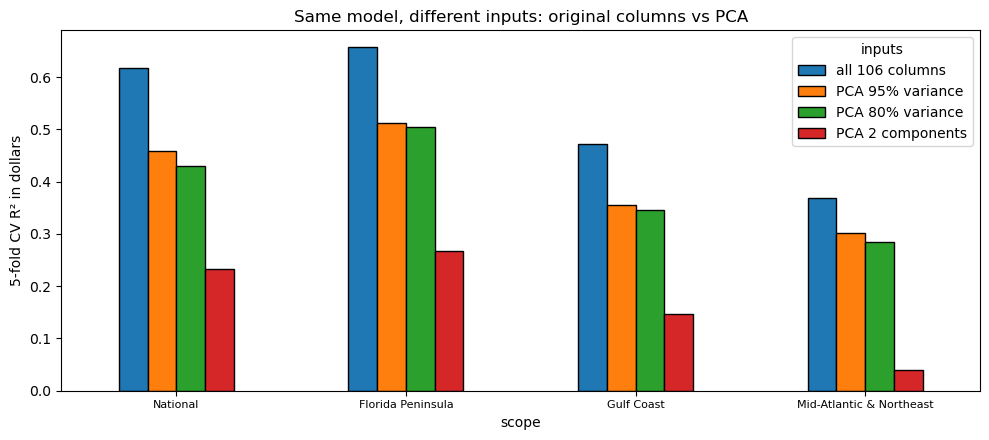

In [16]:
ax = t.drop(columns='columns (national)').T.plot.bar(edgecolor='black', rot=0, figsize=(10, 4.5))
ax.set_ylabel('5-fold CV R² in dollars'); ax.set_title('Same model, different inputs: original columns vs PCA')
ax.tick_params(axis='x', labelsize=8); plt.tight_layout(); plt.show()

**What PCA shows**
- **PCA makes RQ1 clearly worse in every scope.** Nationally, R² falls from about 0.62 (all columns) to about 0.43-0.46 with PCA.
- **PCA barely shrinks this data:** 80% of the variance needs about **45 of 106** components, because most columns are 0/1 one-hot
  columns that are not correlated with each other.
- **PCA keeps the directions where the inputs vary most, not the ones that matter for the payment.** Building coverage, the strongest
  feature, is mixed into components with many weak columns, and the trees can no longer split on it cleanly.
- **Feature selection is the better way to reduce here:** about 15 selected features (4.2) score about 0.59 nationally,
  far above 45 PCA components.
- With median-filled blanks, the national score on all columns is about 0.62, higher than the 0.57 in 4.1 where the model handles blanks
  itself. The regions change by less than 0.01, so we treat this difference as fold-to-fold noise and do not use it in the answer.

---
# Section 5: Answer to RQ1

## Known storms: 5-fold cross validation (the numbers we report)

| Scope | All features (40) | About 15 selected features | Single 70/30 split (Section 2) |
|---|---|---|---|
| **National** | 0.57 (± 0.06) | **0.59** (± 0.05) | 0.649 |
| **Florida Peninsula** | **0.67** (± 0.03) | 0.65 | 0.670 |
| **Gulf Coast** | **0.47** (± 0.03) | 0.44 | 0.458 |
| **Mid-Atlantic & Northeast** | **0.37** (± 0.05) | 0.34 | 0.311 |

- **The single split was lucky for the national model** (0.649 vs a CV mean of 0.57); the regional numbers hold up.
- **About 15 features are enough**; nationally they are as good as all 40 (Section 4.2).
- **PCA does not help:** it lowers R² in every scope (Section 4.3).

## Single 70/30 split: best model per scope (Section 2)

| Scope | Best model | R² dollars | Median error | Mean error |
|---|---|---|---|---|
| **National** | all regions, all groups | **0.649** | $22,462 | $39,601 |
| **Florida Peninsula** | this region only, all groups | **0.670** | $28,078 | $46,531 |
| **Gulf Coast** | this region only, all groups | **0.458** | $17,741 | $26,623 |
| **Mid-Atlantic & Northeast** | this region only, all groups | **0.311** | $13,215 | $26,787 |

- **All 14 groups beat the 15 features everywhere**: national 0.566 → 0.649, Florida 0.567 → 0.660 (national model) and 0.609 → 0.670 (regional model).
- **A model for the region alone is a little better** than the national model in every region (Florida 0.670 vs 0.660, Gulf 0.458 vs 0.416, Northeast 0.311 vs 0.304).
- **Accuracy depends a lot on the region**: Florida's payments are about twice as predictable as the Northeast's.

## New storms (train 2020-2023, test 2024-2025): best model per scope

| Scope | Best model | R² dollars |
|---|---|---|
| National | all regions, 15 features | -0.059 |
| Florida Peninsula | all regions, 15 features | -0.114 |
| Gulf Coast | all regions, 15 features | 0.128 |
| **Mid-Atlantic & Northeast** | all regions, all groups | **0.302** |

- **For Florida and the country as a whole, no model predicts the dollars of a new storm** (all below zero). The extra features make it worse (Florida -0.46), because Helene and Milton were very different from the earlier storms.
- **The Mid-Atlantic & Northeast is the exception**: even on new storms the model explains about **30%**. Its floods are smaller and more alike from year to year.
- On new storms, **the national model beats the regional models**: it has seen more kinds of floods.

## Which features matter (known storms)
- **Building coverage** is the most important feature in every scope: payments are capped by the insurance bought.
- **Florida:** policy count (big condo buildings), **loss year** and storm history. In a random split the loss year mostly tells the model *which hurricane* it was (2022 = Ian, 2024 = Helene and Milton).
- **Gulf Coast:** county history and whether the building is **elevated**.
- **Mid-Atlantic & Northeast:** no feature stands out after coverage; county history, report delay and storm history each add a little.

## Answer to RQ1 in plain words
> **Yes, for claims from a storm that is already happening:** using flood-zone, construction, policy and geographic features plus the storm's and county's claim history,
> gradient boosting explains about **57-59%** of the dollar amount nationally and **67%** in Florida, but only **47%** on the Gulf Coast and **37%** in the Mid-Atlantic & Northeast
> (5-fold cross validation). About 15 well-chosen features are enough; PCA does not help.
> A model trained for the region is slightly better than the national model.
> **For a future storm, mostly no:** the dollar amount cannot be predicted nationally or in Florida, and only partly in the Mid-Atlantic & Northeast (about 20-30%).
> The missing piece is the strength of the flood itself (rainfall, surge height, river levels).

**Note:** the "all groups" set includes latitude and longitude, as chosen by the feature search in notebook 05. In notebooks 02-04 and the regional notebooks they were left out; here we follow the search result.